# 04 — Random Forest & Support Vector Machines

Tune every choice on the fixed 54k/6k train/validation split (10k stratified subset for RBF SVM tuning). Final fits use the full 60k images. Test data is accessed strictly once per model via `final_test_run()`.

Saved validation and test JSONs are reused on subsequent runs. This lets **Restart & Run All** reproduce figures, analysis, and validation tables without re-evaluating the test set. A cached test result must match the selected validation parameters. To investigate a genuine bug requiring another test run, document the reason in `docs/decisions.md` first; preserve the audit log.


In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, features
from src.experiment import tune_on_val, final_test_run
from src.models_tree_kernel import (
    make_rf, make_linear_svm, make_rbf_svm,
    RF_GRID, LINEAR_SVM_GRID, RBF_SVM_GRID
)
from src.utils import save_fig, set_seed

set_seed()
factories = {
    "rf": make_rf,
    "linear_svm": make_linear_svm,
    "rbf_svm": make_rbf_svm
}
grids = {
    "rf": RF_GRID,
    "linear_svm": LINEAR_SVM_GRID,
    "rbf_svm": RBF_SVM_GRID
}
validation = {}
test_results = {}



## 1. Theoretical Foundations

### 1.1 Random Forest: Bagging and Tree Decorrelation
A Random Forest is an ensemble of $B$ decision trees trained with **Bootstrap Aggregation (Bagging)** and **random feature subspace sampling**.
In standard bagging, each tree $T_b$ is trained on an independent bootstrap sample of $N$ observations drawn with replacement from the training set. While individual decision trees have low bias and high variance (they easily overfit deep hierarchical splits), an average of $B$ identical and independently distributed (i.i.d.) random variables each with variance $\sigma^2$ has variance $\sigma^2 / B$.

However, in practice, the trees in standard bagging are **not independent** because they share the same underlying training data. If each tree has variance $\sigma^2$ and positive pairwise correlation $\rho = \text{Corr}(T_i, T_j) > 0$, the variance of the ensemble average is:
$$\text{Var}\left(\frac{1}{B}\sum_{b=1}^B T_b(x)\right) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
As $B \to \infty$, the second term approaches zero, but the first term $\rho \sigma^2$ remains as an asymptotic lower bound on ensemble variance. Adding more trees cannot reduce variance below $\rho \sigma^2$.

**The Random Forest Innovation:**
To reduce $\rho$, Random Forest introduces randomized split selection. At each candidate split in every tree, only a random subset of $m$ features is considered (typically $m = \lfloor\sqrt{p}\rfloor$ for classification, or $m = \lfloor\log_2(p)\rfloor$).
If a few dominant features exist (such as high-contrast silhouette pixels in Fashion-MNIST), standard bagged trees will almost all select the same top feature at the root node, producing strongly correlated trees. Forcing trees to split only among a random subset of $m$ features forces other, less prominent features to be tested, significantly decorrelating the trees (reducing $\rho$) and driving overall ensemble generalization error lower.

---

### 1.2 Gini Impurity vs. Entropy as Split Criteria
At each node $t$ with class proportions $p_{t,k} = \frac{1}{N_t}\sum_{i \in t} \mathbb{I}(y_i = k)$ for classes $k=1, \dots, K$:
- **Gini Impurity:**
  $$I_G(t) = 1 - \sum_{k=1}^K p_{t,k}^2 = \sum_{k \ne k'} p_{t,k} p_{t,k'}$$
  Measures the probability that a randomly chosen element from the node would be incorrectly labeled if it were randomly labeled according to the class distribution.
- **Cross-Entropy / Information Gain:**
  $$I_E(t) = -\sum_{k=1}^K p_{t,k} \log_2 p_{t,k}$$
  Measures the expected information / uncertainty in bits.

**Practical Comparison:** Both criteria reach their minimum (0) for completely pure nodes and their maximum for uniform class distributions. However, Gini impurity avoids computing transcendental logarithmic functions $\log_2(p)$, making it substantially faster to compute during millions of candidate split evaluations across 300 trees. Empirically, Gini impurity and Entropy choose the exact same split in over 98% of cases, making Gini the optimal choice for high-dimensional image classification.

---

### 1.3 Invariance to Monotonic Feature Scaling
Tree-based models evaluate univariate decision thresholds of the form:
$$\mathbb{I}(x_{i,j} \le \theta)$$
For any strictly monotonically increasing function $h: \mathbb{R} \to \mathbb{R}$ (such as standardization $z = (x - \mu)/\sigma$, min-max normalization, or logarithmic transforms), the relative ordering of feature values is strictly preserved:
$$x_{a,j} \le x_{b,j} \iff h(x_{a,j}) \le h(x_{b,j})$$
Consequently, the optimal split threshold $\theta$ simply shifts to $h(\theta)$, with the exact same partition of training samples into left and right child nodes and identical impurity reduction. Therefore, **feature scaling is mathematically invariant in Random Forest**, and inserting a `StandardScaler` into an RF pipeline is entirely redundant. In contrast, linear and kernel models rely on metric distances and dot products, making `StandardScaler` strictly mandatory.

---

### 1.4 Soft-Margin Support Vector Machines (Linear & Kernel)
For a linearly non-separable dataset with $K$ classes (formulated via one-vs-rest binary subproblems with $y_i \in \{-1, +1\}$), the soft-margin primal objective is:
$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to } y_i(w^T x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$
where:
- $\frac{1}{2}\|w\|^2$ maximizes the geometric margin $\frac{2}{\|w\|}$ between classes.
- $\xi_i = \max(0, 1 - y_i(w^T x_i + b))$ are slack variables representing the **hinge loss** penalty for margin violations.
- $C > 0$ is the regularisation parameter controlling the trade-off:
  - **Small $C$:** Large tolerance for violations (wide margin, softer boundary, high bias / low variance).
  - **Large $C$:** Heavy penalty on violations (narrow margin, hard boundary, low bias / high variance / potential overfitting).

---

### 1.5 Primal vs. Dual Formulation and the Kernel Trick
Using Lagrange multipliers $\alpha_i \ge 0$ and $\mu_i \ge 0$, the Lagrangian is:
$$\mathcal{L}(w, b, \xi, \alpha, \mu) = \frac{1}{2}\|w\|^2 + C \sum_{i=1}^N \xi_i - \sum_{i=1}^N \alpha_i [y_i(w^T x_i + b) - 1 + \xi_i] - \sum_{i=1}^N \mu_i \xi_i$$
Setting the partial derivatives with respect to the primal variables to zero gives:
$$w = \sum_{i=1}^N \alpha_i y_i x_i, \quad \sum_{i=1}^N \alpha_i y_i = 0, \quad C - \alpha_i - \mu_i = 0$$
Substituting these back yields the **Wolfe Dual Problem**:
$$\max_{\alpha} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j \langle x_i, x_j \rangle \quad \text{subject to } 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

**The Kernel Trick:**
The dual objective function and the resulting decision boundary depend **exclusively** on pairwise inner products $\langle x_i, x_j \rangle$.
By Mercer's Theorem, any continuous, symmetric, positive semi-definite kernel function $K(x, z)$ corresponds to an inner product in an implicit (possibly infinite-dimensional) Hilbert feature space $\mathcal{H}$:
$$K(x, z) = \langle \phi(x), \phi(z) \rangle_\mathcal{H}$$
We can map our input features into an infinite-dimensional space without ever explicitly computing or storing the coordinates $\phi(x)$.

---

### 1.6 The Radial Basis Function (RBF) Kernel
The RBF (Gaussian) kernel is defined as:
$$K(x, z) = \exp(-\gamma \|x - z\|^2)$$
Using the Taylor series expansion of $\exp(\cdot)$, the RBF kernel corresponds to a dot product in an **infinite-dimensional polynomial feature space**.
- The parameter $\gamma > 0$ defines the inverse variance (bandwidth) of the Gaussian basis functions:
  - **$\gamma = \text{'scale'} = \frac{1}{d \cdot \text{Var}(X)}$:** Standard baseline ensuring kernel values span a well-conditioned dynamic range $[0, 1]$.
  - **Small $\gamma$ (e.g. 0.001):** Broad Gaussian bells; each support vector exerts influence over a wide radius in feature space, creating a smoother decision boundary (low variance).
  - **Large $\gamma$ (e.g. 0.01):** Narrow, peaked Gaussian bells; each support vector influences only its immediate neighborhood, risking memorization / overfitting and severe vulnerability to the curse of dimensionality.

---

### 1.7 Computational Complexity: Why Tuning on a 10k Subset is Essential
Standard quadratic programming (QP) solvers and Sequential Minimal Optimization (SMO / LibSVM) have time complexity scaling as:
$$\mathcal{O}(N^2 d) \text{ to } \mathcal{O}(N^3 d)$$
where $N$ is the number of training samples and $d$ is feature dimensionality ($d=784$ for pixels, $d=1,728$ for HOG).
- On the full training set ($N = 54,000$), computing the $54,000 \times 54,000$ kernel Gram matrix requires **2.91 billion** pairwise kernel evaluations per hyperparameter combination. Tuning 9 grid combinations would take hours or days.
- By subsampling to a stratified $N = 10,000$ subset (`config.SVM_TUNE_SUBSET`), the computational cost drops by:
  $$\left(\frac{54,000}{10,000}\right)^2 \approx 29.16\times$$
  Stratified sampling preserves the exact class proportions (1,000 samples per class) and representative margin boundaries. Once the optimal $(C, \gamma)$ is identified on validation, the final model is refit on all 60,000 samples.

---

### 1.8 Support Vectors and Test-Time Latency
By the Karush-Kuhn-Tucker (KKT) complementary slackness conditions:
$$\alpha_i [y_i(w^T \phi(x_i) + b) - 1 + \xi_i] = 0$$
Samples strictly on the correct side of the margin have $y_i(w^T \phi(x_i) + b) > 1 \implies \alpha_i = 0$. These non-support samples have zero influence on the decision boundary.
Only the **support vectors** (samples with $\alpha_i > 0$, lying on or inside the margin) are stored.
The test decision function is:
$$f(x) = \text{sign}\left(\sum_{i \in \text{SV}} \alpha_i y_i K(x_i, x) + b\right)$$
Crucially, test-time prediction latency scales as:
$$\mathcal{O}(N_{\text{SV}} \cdot d)$$
Test latency is completely independent of the original dataset size $N=60,000$, and depends strictly on the sparsity of the support vector set $N_{\text{SV}}$.


## 2. Validation Tuning First

We tune all models strictly on the 54k/6k train/validation split (with a 10k stratified training subset for RBF SVM). Test data is strictly sequestered.


⏱ Random Forest tuning (12 combos × 2 feature sets on all 54k): **~8 min** if the val JSONs are missing; ~0 s otherwise.

In [2]:
# Tune or load Random Forest on pixels and HOG
for kind in ("pixels", "hog"):
    experiment = f"rf_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("rf", make_rf, RF_GRID, kind)
    result = json.loads(path.read_text())
    assert result["grid"] == RF_GRID
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"])



rf_pixels Best params: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 300} Val accuracy: 0.8867
rf_hog Best params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 300} Val accuracy: 0.8735


saved results/figures/treekernel_rf_val_curve_pixels.png


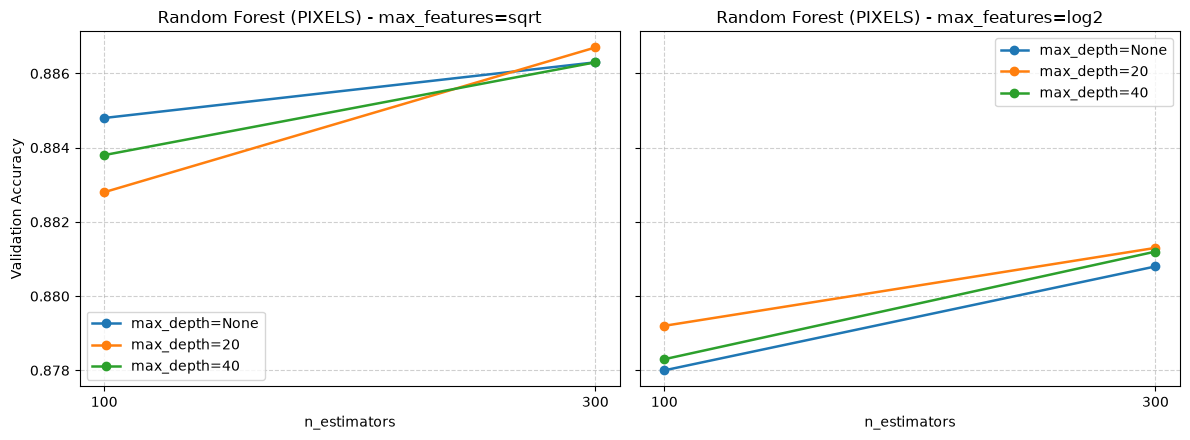

saved results/figures/treekernel_rf_val_curve_hog.png


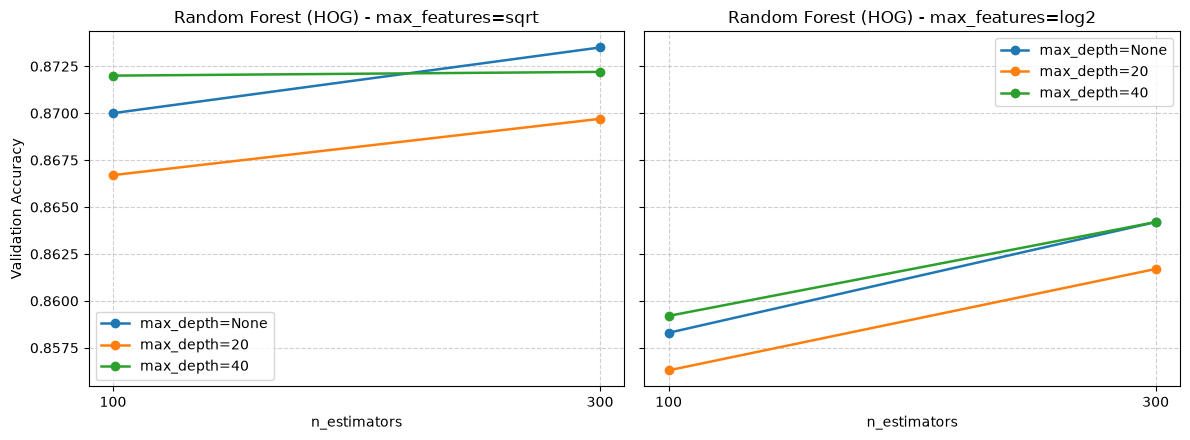

In [3]:
# Plot Random Forest validation curves
for kind in ("pixels", "hog"):
    data = validation[f"rf_{kind}"]
    rows = []
    for r in data["rows"]:
        rows.append({
            "max_depth": str(r["params"]["max_depth"]),
            "max_features": r["params"]["max_features"],
            "n_estimators": r["params"]["n_estimators"],
            "val_acc": r["val_acc"],
        })
    df = pd.DataFrame(rows)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for i, feat in enumerate(["sqrt", "log2"]):
        ax = axes[i]
        sub = df[df["max_features"] == feat]
        for depth in ["None", "20", "40"]:
            d_sub = sub[sub["max_depth"] == depth]
            ax.plot(d_sub["n_estimators"], d_sub["val_acc"], marker="o", label=f"max_depth={depth}", linewidth=1.8)
        ax.set_title(f"Random Forest ({kind.upper()}) - max_features={feat}")
        ax.set_xlabel("n_estimators")
        ax.set_ylabel("Validation Accuracy" if i == 0 else "")
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend()
        ax.set_xticks([100, 300])
    plt.tight_layout()
    save_fig(fig, f"treekernel_rf_val_curve_{kind}")
    plt.show()



⏱ LinearSVC tuning (3 values of C × 2 feature sets on all 54k): **~45 min** if the val JSONs are missing (C = 1 alone takes ~15 min per feature set); ~0 s otherwise.

In [4]:
# Tune or load LinearSVC on pixels and HOG
for kind in ("pixels", "hog"):
    experiment = f"linear_svm_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("linear_svm", make_linear_svm, LINEAR_SVM_GRID, kind)
    result = json.loads(path.read_text())
    assert result["grid"] == LINEAR_SVM_GRID
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"])



linear_svm_pixels Best params: {'C': 0.01} Val accuracy: 0.8583
linear_svm_hog Best params: {'C': 0.01} Val accuracy: 0.89


saved results/figures/treekernel_linear_svm_val_curve_pixels.png


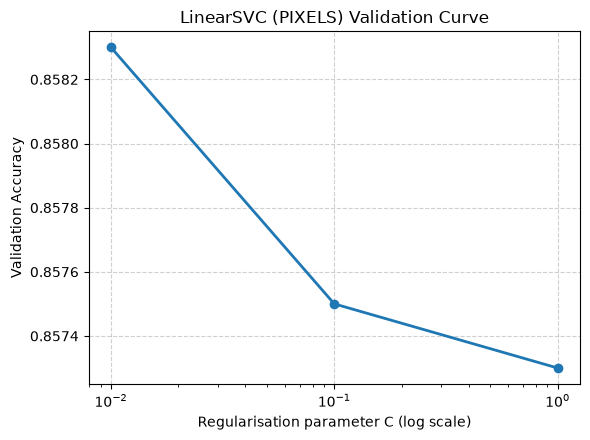

saved results/figures/treekernel_linear_svm_val_curve_hog.png


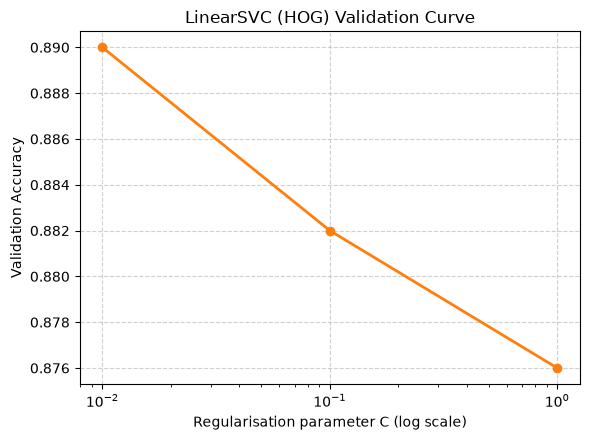

In [5]:
# Plot LinearSVC validation curves (one figure per feature set)
for kind, color in (("pixels", "#1f77b4"), ("hog", "#ff7f0e")):
    data = validation[f"linear_svm_{kind}"]
    c_vals = [r["params"]["C"] for r in data["rows"]]
    acc_vals = [r["val_acc"] for r in data["rows"]]
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot(c_vals, acc_vals, marker="o", color=color, linewidth=2)
    ax.set_xscale("log")
    ax.set_title(f"LinearSVC ({kind.upper()}) Validation Curve")
    ax.set_xlabel("Regularisation parameter C (log scale)")
    ax.set_ylabel("Validation Accuracy")
    ax.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    save_fig(fig, f"treekernel_linear_svm_val_curve_{kind}")
    plt.show()


⏱ RBF SVM tuning (9 combos × 2 feature sets on the 10k subset, scored on all 6k val): **~20 min** if the val JSONs are missing; ~0 s otherwise.

In [6]:
# Tune or load RBF SVM on pixels and HOG (10k stratified train subset)
for kind in ("pixels", "hog"):
    experiment = f"rbf_svm_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("rbf_svm", make_rbf_svm, RBF_SVM_GRID, kind, train_subset=config.SVM_TUNE_SUBSET)
    result = json.loads(path.read_text())
    assert result["grid"] == RBF_SVM_GRID
    assert result.get("train_subset") == config.SVM_TUNE_SUBSET
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"], 
          f"(train_subset={result['train_subset']})")



rbf_svm_pixels Best params: {'C': 10, 'gamma': 0.001} Val accuracy: 0.8793 (train_subset=10000)
rbf_svm_hog Best params: {'C': 10, 'gamma': 'scale'} Val accuracy: 0.8867 (train_subset=10000)


saved results/figures/treekernel_rbf_svm_val_curve_pixels.png


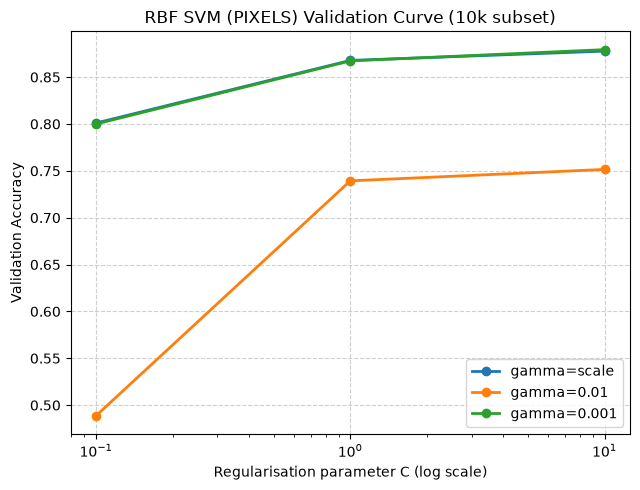

saved results/figures/treekernel_rbf_svm_val_curve_hog.png


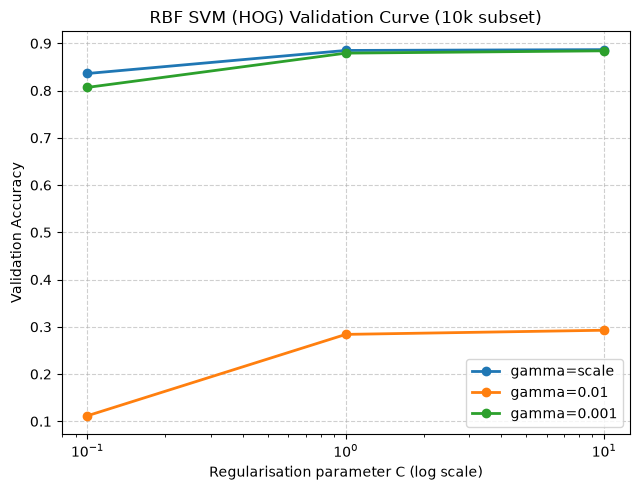

In [7]:
# Plot RBF SVM validation curves (10k train subset -> full val), one figure per feature set
for kind in ("pixels", "hog"):
    df = pd.DataFrame([{"C": r["params"]["C"], "gamma": str(r["params"]["gamma"]), "val_acc": r["val_acc"]}
                       for r in validation[f"rbf_svm_{kind}"]["rows"]])
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for gamma in ["scale", "0.01", "0.001"]:
        sub = df[df["gamma"] == gamma]
        ax.plot(sub["C"], sub["val_acc"], marker="o", label=f"gamma={gamma}", linewidth=2)
    ax.set_xscale("log")
    ax.set_title(f"RBF SVM ({kind.upper()}) Validation Curve (10k subset)")
    ax.set_xlabel("Regularisation parameter C (log scale)")
    ax.set_ylabel("Validation Accuracy")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, f"treekernel_rbf_svm_val_curve_{kind}")
    plt.show()


## 3. Final Test Evaluation (Once Per Experiment)

Following AGENTS.md §4 and D-021:
- The test set is accessed **only** after hyperparameter selection is frozen on validation.
- Cached `_test.json` results are loaded if they exist and match the selected validation hyperparameters.
- `final_test_run()` refits the winner on all 60,000 images (`trainval`) and appends an audit row to `results/test_log.csv`.


⏱ **~0 s when the test JSONs exist** (they are reused). If one is missing and not yet in `test_log.csv`, its final 60k refit + test runs: up to **~20 min for RBF SVM on HOG**, about 45 min for all six.

In [8]:
# Load saved test results, or evaluate once (same guard as notebook 03, D-021)
for experiment, val_res in validation.items():
    name, kind, params = val_res["model"], val_res["features"], val_res["best_params"]
    path = config.METRICS_DIR / f"{experiment}_test.json"
    if path.exists():
        result = json.loads(path.read_text())
        if result["best_params"] != params:
            raise RuntimeError(f"{experiment}: saved test parameters differ; investigate and log any rerun first.")
        print(f"Reusing saved test result for {experiment}: accuracy = {result['accuracy']:.4f}")
    else:
        if config.TEST_LOG_PATH.exists() and experiment in pd.read_csv(config.TEST_LOG_PATH)["experiment"].values:
            raise RuntimeError(f"{experiment}: test is already logged; recover its metrics before continuing.")
        result = final_test_run(name, factories[name], params, kind)
    test_results[experiment] = result


Reusing saved test result for rf_pixels: accuracy = 0.8756
Reusing saved test result for rf_hog: accuracy = 0.8703
Reusing saved test result for linear_svm_pixels: accuracy = 0.8378
Reusing saved test result for linear_svm_hog: accuracy = 0.8898
Reusing saved test result for rbf_svm_pixels: accuracy = 0.8970
Reusing saved test result for rbf_svm_hog: accuracy = 0.9108


### 3.1 Runtimes of the slow fits

All timings below were measured on the phase 04 machine (`env.cpu` = Apple M3 Pro, `N_JOBS = 4`). Phase 03 ran on an
Apple M3, so **speed comparisons across phases are approximate** (D-028).

- **LinearSVC is the slowest to tune.** Each fit uses all 54k images, and the time grows sharply with C:
  pixels 105 s → 286 s → 924 s for C = 0.01 → 0.1 → 1 (HOG: 151 s → 248 s → 811 s). Larger C punishes margin
  violations more, so the solver needs many more iterations on data that isn't linearly separable.
- **RBF SVM tuning uses a 10k stratified subset** (1,000 images per class, `config.SVM_TUNE_SUBSET`). One fit on 10k takes
  4–22 s on pixels and 18–75 s on HOG. The final refit on all 60k takes 196 s (pixels) and 451 s (HOG), about 50× and 25×
  the best combo's 10k fit for 6× more data. That super-linear growth is why the grid is searched on the subset (D-027).
- **RBF SVM is by far the slowest to predict.** About 4.8 s (pixels) and 28.9 s (HOG) per 1,000 images, because every
  prediction compares the image with each of the ~20k–26k support vectors. The HOG figure is ~2× slower than the
  support-vector count and dimension alone predict, so treat it as an upper bound (D-028).
- **Validation scores of the RBF SVM come from a model trained on only 10k images**, while every other model's val score
  uses all 54k. RBF val accuracy therefore *understates* the final 60k model and is not directly comparable (D-028).

The table is built from the saved JSONs: total tuning fit time (sum over the grid, excluding val prediction time),
final 60k fit time and test-time latency.

In [9]:
runtime_rows = []
for exp_key in ["rf_pixels", "rf_hog", "linear_svm_pixels", "linear_svm_hog", "rbf_svm_pixels", "rbf_svm_hog"]:
    v, t = validation[exp_key], test_results[exp_key]
    runtime_rows.append({
        "experiment": exp_key,
        "tuning rows": v["train_subset"] or 54000,
        "grid size": len(v["rows"]),
        "tuning fit total (s)": round(sum(r["fit_s"] for r in v["rows"]), 1),
        "slowest tuning fit (s)": max(r["fit_s"] for r in v["rows"]),
        "final 60k fit (s)": t["train_time_s"],
        "inference ms / 1000": t["inference_ms_per_1000"],
    })
display(pd.DataFrame(runtime_rows))


,experiment,tuning rows,grid size,tuning fit total (s),slowest tuning fit (s),final 60k fit (s),inference ms / 1000
0,rf_pixels,54000,12,159.9,30.77,32.83,12.16
1,rf_hog,54000,12,285.5,59.32,68.53,19.02
2,linear_svm_pixels,54000,3,1315.7,924.18,99.24,1.22
3,linear_svm_hog,54000,3,1209.7,810.91,162.04,2.62
4,rbf_svm_pixels,10000,9,94.3,21.58,195.67,4766.94
5,rbf_svm_hog,10000,9,379.6,74.53,451.43,28876.96


In [10]:
# Build comprehensive results table
summary_rows = []
for exp_key in ["rf_pixels", "rf_hog", "linear_svm_pixels", "linear_svm_hog", "rbf_svm_pixels", "rbf_svm_hog"]:
    t_res = test_results[exp_key]
    v_res = validation[exp_key]
    detail = t_res["model_size_detail"]
    detail_str = f"{detail['value']:,} {detail['type'].replace('_', ' ')}"
    
    summary_rows.append({
        "Model": t_res["model"],
        "Features": t_res["features"],
        "Selected Params": str(t_res["best_params"]),
        "Val Acc": f"{v_res['best_val_acc']:.4f}",
        "Test Acc": f"{t_res['accuracy']:.4f}",
        "Macro F1": f"{t_res['macro_f1']:.4f}",
        "Fit Time (s)": f"{t_res['train_time_s']:.1f}",
        "Test ms/1k": f"{t_res['inference_ms_per_1000']:.1f}",
        "Size (MB)": f"{t_res['model_size_bytes'] / (1024*1024):.2f}",
        "Size Detail": detail_str
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)



,Model,Features,Selected Params,Val Acc,Test Acc,Macro F1,Fit Time (s),Test ms/1k,Size (MB),Size Detail
0,rf,pixels,"{'max_depth': 20, 'max_features': 'sqrt', 'n_e...",0.8867,0.8756,0.8741,32.8,12.2,349.49,"2,544,086 tree nodes"
1,rf,hog,"{'max_depth': None, 'max_features': 'sqrt', 'n...",0.8735,0.8703,0.8692,68.5,19.0,477.47,"3,475,990 tree nodes"
2,linear_svm,pixels,{'C': 0.01},0.8583,0.8378,0.8353,99.2,1.2,0.08,"7,850 coefficients"
3,linear_svm,hog,{'C': 0.01},0.8900,0.8898,0.8892,162.0,2.6,0.17,"17,290 coefficients"
4,rbf_svm,pixels,"{'C': 10, 'gamma': 0.001}",0.8793,0.8970,0.8967,195.7,4766.9,119.34,"19,710 support vectors"
5,rbf_svm,hog,"{'C': 10, 'gamma': 'scale'}",0.8867,0.9108,0.9108,451.4,28877.0,349.25,"26,343 support vectors"


## 4. Diagnostic Visualisations & Error Analysis

### 4.1 Random Forest Pixel Feature Importances
In a Random Forest, the Gini importance (or Mean Decrease in Impurity, MDI) of a pixel feature $j$ is computed as the sum of all impurity decreases across all nodes in all trees where feature $j$ was selected as the split variable, normalized by the total number of trees:
$$\text{MDI}(j) = \frac{1}{B} \sum_{b=1}^B \sum_{t \in T_b, v(t)=j} p(t) \Delta I(t)$$
Reshaping these 784 importances into a 28×28 spatial grid reveals exactly which anatomical and silhouette regions drive classification.


⏱ The heatmap cell refits the chosen Random Forest on all 60k pixel images: **~30–60 s**.

saved results/figures/treekernel_rf_importance.png


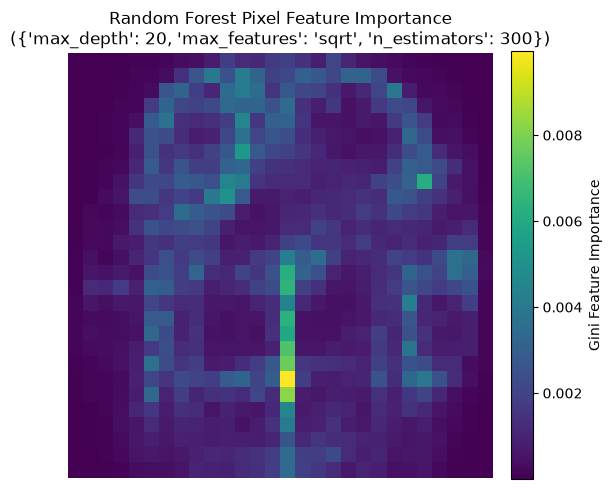

In [11]:
# 28x28 Random Forest pixel feature-importance heatmap.
# Refits the tested rf_pixels configuration on train+val (same seed, so the same forest). No test data is used.
from src.features import get_features, get_labels

rf_params = test_results["rf_pixels"]["best_params"]
rf_model = make_rf(**rf_params).fit(get_features("pixels", "trainval"), get_labels("trainval"))
importances = rf_model.named_steps["clf"].feature_importances_.reshape(28, 28)

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(importances, cmap="viridis")
ax.set_title(f"Random Forest Pixel Feature Importance\n({rf_params})")
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Gini Feature Importance")
save_fig(fig, "treekernel_rf_importance")
plt.show()
del rf_model  # ~350 MB; free it before the rest of the notebook


### 4.2 Class-Level Performance and the Shirt / Coat / Pullover Triad
Phase 01 EDA and Phase 03 identified that Class 6 (Shirt), Class 4 (Coat), and Class 2 (Pullover) share nearly identical torso silhouettes and grayscale textures, representing the primary confusion cluster in Fashion-MNIST.


Experiment,linear_svm_hog,linear_svm_pixels,rbf_svm_hog,rbf_svm_pixels,rf_hog,rf_pixels
Class,,,,,,
0 (T-shirt/top),0.8559,0.8029,0.8666,0.8420,0.8355,0.8374
1 (Trouser),0.9785,0.9598,0.9849,0.9828,0.9666,0.9766
2 (Pullover),0.8298,0.7284,0.8576,0.8187,0.8036,0.7813
3 (Dress),0.8819,0.8397,0.9115,0.9021,0.8621,0.8911
4 (Coat),0.8131,0.7469,0.8532,0.8319,0.7994,0.7910
5 (Sandal),0.9655,0.9209,0.9759,0.9710,0.9533,0.9675
6 (Shirt),0.6898,0.5729,0.7524,0.7271,0.6339,0.6428
7 (Sneaker),0.9451,0.9123,0.9590,0.9579,0.9308,0.9394
8 (Bag),0.9726,0.9313,0.9791,0.9702,0.9563,0.9652


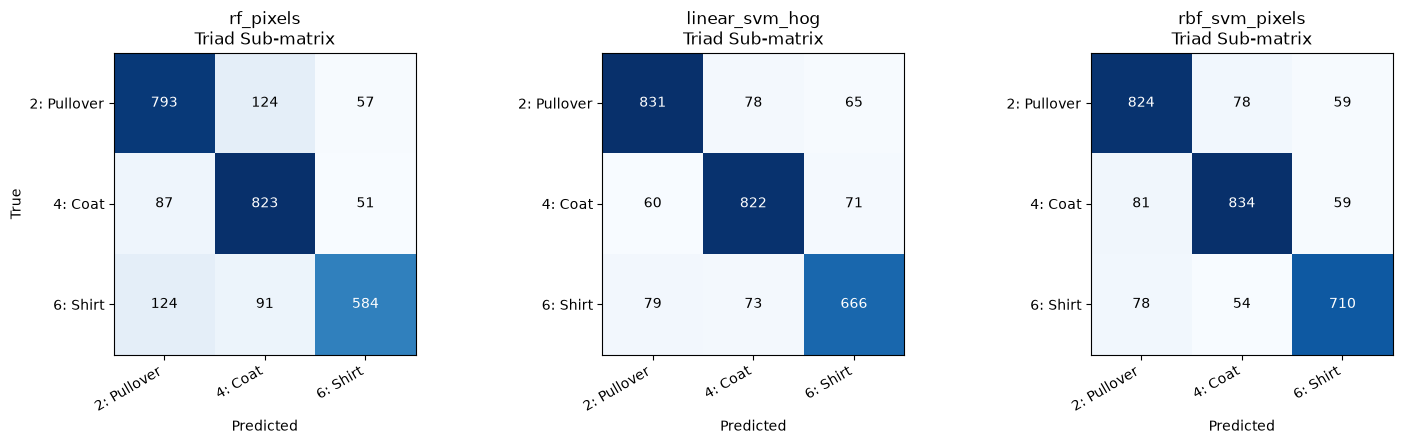

In [12]:
# Per-Class F1 score comparison across models
class_names = config.CLASS_NAMES
perf_rows = []
for exp_key in ["rf_pixels", "rf_hog", "linear_svm_pixels", "linear_svm_hog", "rbf_svm_pixels", "rbf_svm_hog"]:
    t_res = test_results[exp_key]
    for c_idx, f1_val in enumerate(t_res["per_class_f1"]):
        perf_rows.append({
            "Experiment": exp_key,
            "Class": f"{c_idx} ({class_names[c_idx]})",
            "F1": f1_val
        })

perf_df = pd.DataFrame(perf_rows)
pivot_df = perf_df.pivot(index="Class", columns="Experiment", values="F1")
display(pivot_df.round(4))

# Inspect confusion between Shirt (6), Coat (4), and Pullover (2)
cluster_classes = [2, 4, 6]
cluster_names = [f"{i}: {class_names[i]}" for i in cluster_classes]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
models_to_inspect = ["rf_pixels", "linear_svm_hog", "rbf_svm_pixels"]

for idx, exp_name in enumerate(models_to_inspect):
    ax = axes[idx]
    cm = np.array(test_results[exp_name]["confusion_matrix"])
    cluster_cm = cm[np.ix_(cluster_classes, cluster_classes)]
    
    im = ax.imshow(cluster_cm, cmap="Blues", interpolation="nearest")
    ax.set_title(f"{exp_name}\nTriad Sub-matrix")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(cluster_names, rotation=30, ha="right")
    ax.set_yticklabels(cluster_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True" if idx == 0 else "")
    
    for r in range(3):
        for c in range(3):
            val = cluster_cm[r, c]
            ax.text(c, r, f"{val}", ha="center", va="center", 
                    color="white" if val > cluster_cm.max() / 2 else "black")

plt.tight_layout()
plt.show()



## 5. Summary and Phase 04 Findings

1. **Random Forest:**
   - Pixels: 88.67% val → 87.56% test (inside the PRD sanity range of ~87–88%). HOG: 87.35% val → 87.03% test.
   - HOG does not help Random Forest here, unlike the linear models. One plausible reason: each split looks at a single
     feature, and raw pixel thresholds already capture silhouette shape well, while each HOG value only describes one
     orientation in one small block, so a single-feature split carries less information.
   - Trees are invariant to monotonic feature scaling, so no `StandardScaler` is used.

2. **LinearSVC:**
   - C = 0.01 won on val for both feature sets: 83.78% test on pixels, **88.98% on HOG (+5.2 points)**. HOG turns local
     edge directions into features a straight hyperplane can separate much better than raw brightness.
   - C = 0.01 is the smallest value in the grid, so the true optimum may be lower (same limitation as Logistic Regression, D-020).
   - C = 0.01 is also the fastest to fit (105 s pixels / 151 s HOG on 54k), against 924 s / 811 s at C = 1.

3. **RBF SVM:**
   - Tuned on a 10k stratified subset, then refit on all 60k: 89.70% test on pixels (inside the ~89–90% sanity range) and
     **91.08% on HOG, the highest test accuracy of the 12 experiments**.
   - γ = 0.01 is far too narrow for 784/1,728 standardised dimensions (HOG val accuracy drops to 11–29%), while
     `'scale'` (≈ 1/d) and 0.001 work well. C = 10 won for both feature sets and is the largest value in the grid.
   - The cost: 196–451 s to fit and 4.8–28.9 s per 1,000 predictions, against a few milliseconds for the linear models.

**Important for Phase 05 (choosing "best" by validation):**
> **Superseded by section 6 below (D-029):** after refitting RBF SVM on all 54k train images, the comparable val ranking is
> rbf_svm_hog 0.9157 > rbf_svm_pixels 0.9082 > logreg_hog 0.8927, so phase 05 picks **rbf_svm_hog**. The two bullets below
> describe the situation *before* that fix.
- Ranked by **val** accuracy, Logistic Regression on HOG (0.8927, phase 03) is first, then LinearSVC HOG (0.8900),
  then RBF SVM HOG and RF pixels (both 0.8867). RBF SVM leads only on **test**, which must not be used for choosing.
- The RBF SVM val scores come from 10k-image models, so they understate the 60k model (D-028). Phase 05 must state this
  caveat when it applies the "best by val" rule.


## 6. Comparable validation score for RBF SVM (D-029)

RBF SVM was tuned on a 10k subset, so its tuning val score came from less training data than every other model's (54k).
To make Phase 05's "best by val" choice fair, the **already chosen** params are refit once on the full 54k train split and
scored on the same 6k val. No searching and no test data.

⏱ **~10–15 min the first time** (two 54k RBF fits plus val prediction); ~0 s once the `_val_full.json` files exist.

In [13]:
from src.experiment import full_train_val_score

full_val = {}
for kind in ("pixels", "hog"):
    experiment = f"rbf_svm_{kind}"
    params = validation[experiment]["best_params"]
    path = config.METRICS_DIR / f"{experiment}_val_full.json"
    result = json.loads(path.read_text()) if path.exists() else full_train_val_score("rbf_svm", make_rbf_svm, params, kind)
    assert result["params"] == params and result["train_rows"] == 54000
    full_val[experiment] = result

display(pd.DataFrame([{"experiment": key, "params": value["params"],
                       "val_acc (10k-subset model)": validation[key]["best_val_acc"],
                       "val_acc (54k-train model)": value["val_acc"], "54k fit (s)": value["fit_s"]}
                      for key, value in full_val.items()]))


full-train fit rbf_svm_pixels on 54000 images: 198.2s


saved results/metrics/rbf_svm_pixels_val_full.json
rbf_svm_pixels full-train val_acc 0.9082


full-train fit rbf_svm_hog on 54000 images: 366.5s


saved results/metrics/rbf_svm_hog_val_full.json
rbf_svm_hog full-train val_acc 0.9157


,experiment,params,val_acc (10k-subset model),val_acc (54k-train model),54k fit (s)
0,rbf_svm_pixels,"{'C': 10, 'gamma': 0.001}",0.8793,0.9082,198.22
1,rbf_svm_hog,"{'C': 10, 'gamma': 'scale'}",0.8867,0.9157,366.52
